# Data Analysis

Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Load Dataset

In [2]:
df = pd.read_csv("jabalpur_raw_data.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'jabalpur_raw_data.csv'

Preview Data

In [ ]:
print(df.head())

                        Date Time  Traffic Total (volume)  \
0           Sums (of 2208 values)          908,366,715 KB   
1       Averages (of 2208 values)              411,398 KB   
2                       Date Time  Traffic Total (volume)   
3  22.12.2025 00:00:00 − 00:05:00              309,862 KB   
4  22.12.2025 00:05:00 − 00:10:00            1,557,152 KB   

   Traffic Total (speed)  Traffic In (volume)  Traffic In (speed)  \
0                    NaN      517,937,243\nKB                 NaN   
1          11,234 kbit/s           234,573 KB        6,405 kbit/s   
2  Traffic Total (speed)  Traffic In (volume)  Traffic In (speed)   
3            8462 kbit/s           212,613 KB      5,806\n kbit/s   
4          42,523 kbit/s           886,130 KB       24,199 kbit/s   

   Traffic Out (volume)  Traffic Out (speed)  Downtime  Coverage  
0        390,429,473 KB                  NaN       NaN       NaN  
1            176,825 KB         4,829 kbit/s        0%      100%  
2  Traffic Out (v

Data Cleaning

In [ ]:
df = df.iloc[3:].reset_index(drop=True)

In [ ]:
df.head()

,Date Time,Traffic Total (volume),Traffic Total (speed),Traffic In (volume),Traffic In (speed),Traffic Out (volume),Traffic Out (speed),Downtime,Coverage
0,22.12.2025 00:00:00 − 00:05:00,"309,862 KB",8462 kbit/s,"212,613 KB","5,806\n kbit/s","97,249 KB",2656 kbit/s,0%,100%
1,22.12.2025 00:05:00 − 00:10:00,"1,557,152 KB","42,523 kbit/s","886,130 KB","24,199 kbit/s","671,021 KB","18,325 kbit/s",0%,100%
2,22.12.2025 00:10:00 − 00:15:00,"1,682,285 KB","45,942 kbit/s","918,735 KB","25,090 kbit/s","763,550 KB","20,852 kbit/s",0%,100%
3,22.12.2025 00:15:00 − 00:20:00,"991,481 KB","27,076 kbit/s","585,040 KB","15,977 kbit/s","406,442 KB","11,099 kbit/s",0%,100%
4,22.12.2025 00:20:00 − 00:25:00,"35,473 KB",969 kbit/s,"2,673 KB",73 kbit/s,"32,800 KB",896 kbit/s,0%,100%


In [ ]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 2208 entries, 0 to 2207
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Date Time               2208 non-null   str  
 1   Traffic Total (volume)  2208 non-null   str  
 2   Traffic Total (speed)   2208 non-null   str  
 3   Traffic In (volume)     2208 non-null   str  
 4   Traffic In (speed)      2208 non-null   str  
 5   Traffic Out (volume)    2208 non-null   str  
 6   Traffic Out (speed)     2208 non-null   str  
 7   Downtime                2208 non-null   str  
 8   Coverage                2208 non-null   str  
dtypes: str(9)
memory usage: 155.4 KB
None


In [ ]:
volume_cols = ["Traffic Total (volume)","Traffic In (volume)","Traffic Out (volume)"]

for col in volume_cols:
    df[col] = (df[col].astype(str).str.replace(",", "", regex=False).str.replace("KB", "", regex=False).str.strip().astype(int))


In [ ]:
speed_cols = ["Traffic Total (speed)","Traffic In (speed)","Traffic Out (speed)"]

for col in speed_cols:
    df[col] = (df[col].astype(str).str.replace(",", "", regex=False).str.replace("kbit/s", "", regex=False).str.replace("\n", "", regex=False).str.strip().astype(int))


In [ ]:
percent_cols = ["Downtime", "Coverage"]

for col in percent_cols:
    df[col] = (df[col].astype(str).str.replace("%", "", regex=False).str.strip().astype(int))


In [ ]:
df["DateTime"] = pd.to_datetime(df["Date Time"].str[:19],format="%d.%m.%Y %H:%M:%S",)

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2208 entries, 0 to 2207
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Date Time               2208 non-null   str           
 1   Traffic Total (volume)  2208 non-null   int64         
 2   Traffic Total (speed)   2208 non-null   int64         
 3   Traffic In (volume)     2208 non-null   int64         
 4   Traffic In (speed)      2208 non-null   int64         
 5   Traffic Out (volume)    2208 non-null   int64         
 6   Traffic Out (speed)     2208 non-null   int64         
 7   Downtime                2208 non-null   int64         
 8   Coverage                2208 non-null   int64         
 9   DateTime                2208 non-null   datetime64[us]
dtypes: datetime64[us](1), int64(8), str(1)
memory usage: 172.6 KB


In [ ]:
df.isnull().sum()

Date Time                 0
Traffic Total (volume)    0
Traffic Total (speed)     0
Traffic In (volume)       0
Traffic In (speed)        0
Traffic Out (volume)      0
Traffic Out (speed)       0
Downtime                  0
Coverage                  0
DateTime                  0
dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.head()

,Date Time,Traffic Total (volume),Traffic Total (speed),Traffic In (volume),Traffic In (speed),Traffic Out (volume),Traffic Out (speed),Downtime,Coverage,DateTime
0,22.12.2025 00:00:00 − 00:05:00,309862,8462,212613,5806,97249,2656,0,100,2025-12-22 00:00:00
1,22.12.2025 00:05:00 − 00:10:00,1557152,42523,886130,24199,671021,18325,0,100,2025-12-22 00:05:00
2,22.12.2025 00:10:00 − 00:15:00,1682285,45942,918735,25090,763550,20852,0,100,2025-12-22 00:10:00
3,22.12.2025 00:15:00 − 00:20:00,991481,27076,585040,15977,406442,11099,0,100,2025-12-22 00:15:00
4,22.12.2025 00:20:00 − 00:25:00,35473,969,2673,73,32800,896,0,100,2025-12-22 00:20:00


In [ ]:
df.describe()

,Traffic Total (volume),Traffic Total (speed),Traffic In (volume),Traffic In (speed),Traffic Out (volume),Traffic Out (speed),Downtime,Coverage,DateTime
count,2.208000e+03,2208.000000,2208.000000,2208.000000,2208.000000,2208.000000,2208.0,2208.0,2208
mean,4.113980e+05,11234.806159,234573.032609,6405.920290,176824.941576,4828.891304,0.0,100.0,2025-12-25 19:57:30
min,1.051300e+04,287.000000,1407.000000,38.000000,9107.000000,249.000000,0.0,100.0,2025-12-22 00:00:00
25%,6.715200e+04,1834.000000,37854.750000,1034.000000,29464.750000,804.750000,0.0,100.0,2025-12-23 21:58:45
50%,2.090075e+05,5708.000000,135467.500000,3699.500000,78166.000000,2134.500000,0.0,100.0,2025-12-25 19:57:30
75%,4.030005e+05,11005.500000,235685.000000,6436.250000,169845.500000,4638.000000,0.0,100.0,2025-12-27 17:56:15
max,1.712855e+06,46774.000000,948030.000000,25889.000000,784893.000000,21434.000000,0.0,100.0,2025-12-29 15:55:00
std,4.794150e+05,13092.274645,267269.334527,7298.814466,214752.983928,5864.647591,0.0,0.0,NaN


Traffic Volume Distribution

In [ ]:
volume_cols = ["Traffic Total (volume)","Traffic In (volume)","Traffic Out (volume)"]


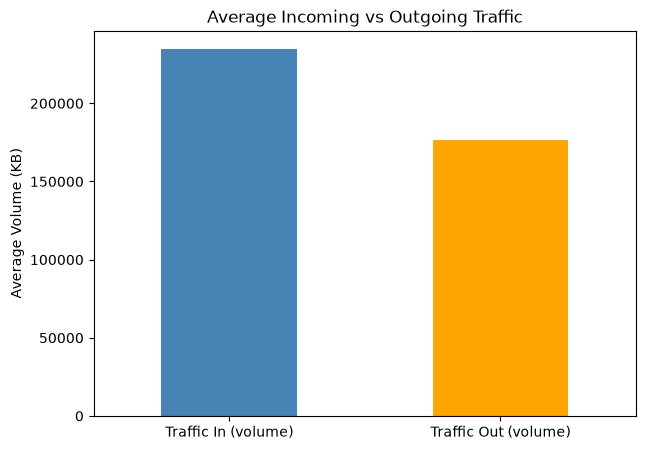

In [ ]:
traffic_direction = df[["Traffic In (volume)", "Traffic Out (volume)"]].mean()

plt.figure(figsize=(7, 5))

traffic_direction.plot(kind="bar",color=["steelblue", "orange"])

plt.ylabel("Average Volume (KB)")
plt.title("Average Incoming vs Outgoing Traffic")
plt.xticks(rotation=0)

plt.show()


In [ ]:
df.nlargest(5,"Traffic Total (volume)")[["Date Time","Traffic Total (volume)","Traffic In (volume)","Traffic Out (volume)"]]


,Date Time,Traffic Total (volume),Traffic In (volume),Traffic Out (volume)
2018,29.12.2025 00:10:00 − 00:15:00,1712855,927962,784893
1730,28.12.2025 00:10:00 − 00:15:00,1701269,928848,772421
1154,26.12.2025 00:10:00 − 00:15:00,1696131,927433,768698
1442,27.12.2025 00:10:00 − 00:15:00,1693490,926431,767059
866,25.12.2025 00:10:00 − 00:15:00,1693281,929722,763559


In [ ]:
df.nsmallest(5,"Traffic Total (volume)")[["Date Time","Traffic Total (volume)","Traffic In (volume)","Traffic Out (volume)"]]


,Date Time,Traffic Total (volume),Traffic In (volume),Traffic Out (volume)
2056,29.12.2025 03:20:00 − 03:25:00,10513,1407,9107
2008,28.12.2025 23:20:00 − 23:25:00,10776,1581,9195
2068,29.12.2025 04:20:00 − 04:25:00,11188,1847,9341
2044,29.12.2025 02:20:00 − 02:25:00,11533,2105,9428
1768,28.12.2025 03:20:00 − 03:25:00,11615,1835,9780


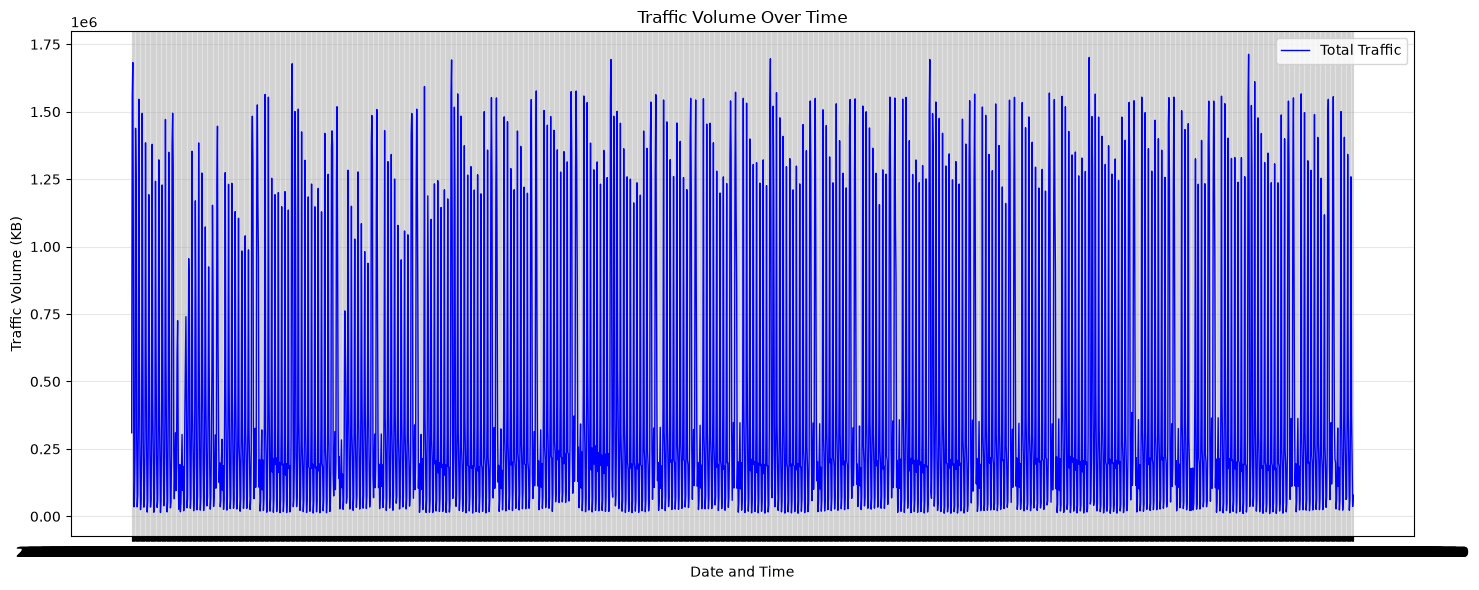

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(df["Date Time"],df["Traffic Total (volume)"],label="Total Traffic",color="blue",linewidth=1)

plt.xlabel("Date and Time")
plt.ylabel("Traffic Volume (KB)")
plt.title("Traffic Volume Over Time")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


Traffic Speed Distribution

In [ ]:
speed_cols = ["Traffic Total (speed)","Traffic In (speed)","Traffic Out (speed)"]

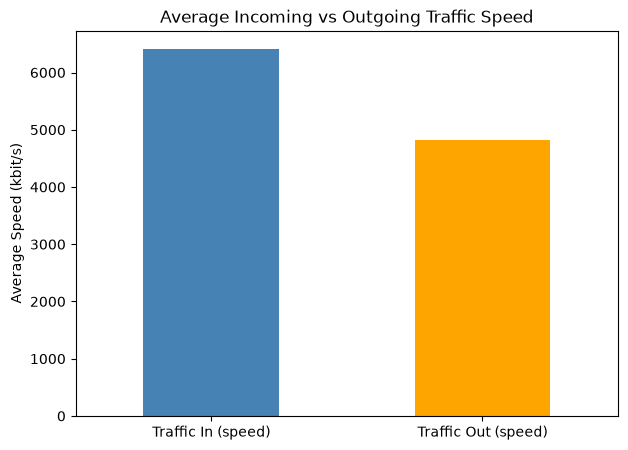

In [ ]:
average_speed = df[["Traffic In (speed)","Traffic Out (speed)"]].mean()

plt.figure(figsize=(7, 5))

average_speed.plot(kind="bar",color=["steelblue", "orange"])

plt.ylabel("Average Speed (kbit/s)")
plt.title("Average Incoming vs Outgoing Traffic Speed")
plt.xticks(rotation=0)

plt.show()


In [ ]:
df.nlargest(5,"Traffic Total (speed)")[["Date Time","Traffic Total (speed)","Traffic In (speed)","Traffic Out (speed)"]]


,Date Time,Traffic Total (speed),Traffic In (speed),Traffic Out (speed)
2018,29.12.2025 00:10:00 − 00:15:00,46774,25340,21434
1730,28.12.2025 00:10:00 − 00:15:00,46461,25366,21094
1154,26.12.2025 00:10:00 − 00:15:00,46319,25327,20992
1442,27.12.2025 00:10:00 − 00:15:00,46248,25300,20948
866,25.12.2025 00:10:00 − 00:15:00,46242,25390,20852


In [ ]:
df.nsmallest(5,"Traffic Total (speed)")[["Date Time","Traffic Total (speed)","Traffic In (speed)","Traffic Out (speed)"]]


,Date Time,Traffic Total (speed),Traffic In (speed),Traffic Out (speed)
2056,29.12.2025 03:20:00 − 03:25:00,287,38,249
2008,28.12.2025 23:20:00 − 23:25:00,294,43,251
2068,29.12.2025 04:20:00 − 04:25:00,306,50,255
2044,29.12.2025 02:20:00 − 02:25:00,315,57,257
1768,28.12.2025 03:20:00 − 03:25:00,317,50,267


Compare Volume and Speed

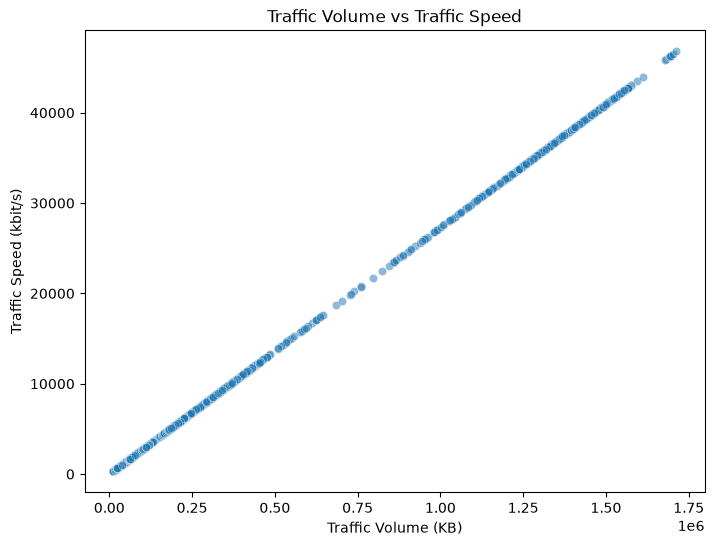

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(data=df,x="Traffic Total (volume)",y="Traffic Total (speed)",alpha=0.5)

plt.xlabel("Traffic Volume (KB)")
plt.ylabel("Traffic Speed (kbit/s)")
plt.title("Traffic Volume vs Traffic Speed")

plt.show()


Traffic by Hour / Time of Day

In [ ]:
df["Hour"] = df["DateTime"].dt.hour
hourly_volume = (df.groupby("Hour")["Traffic Total (volume)"].mean())
hourly_direction = df.groupby("Hour")[["Traffic In (volume)","Traffic Out (volume)"]].mean()

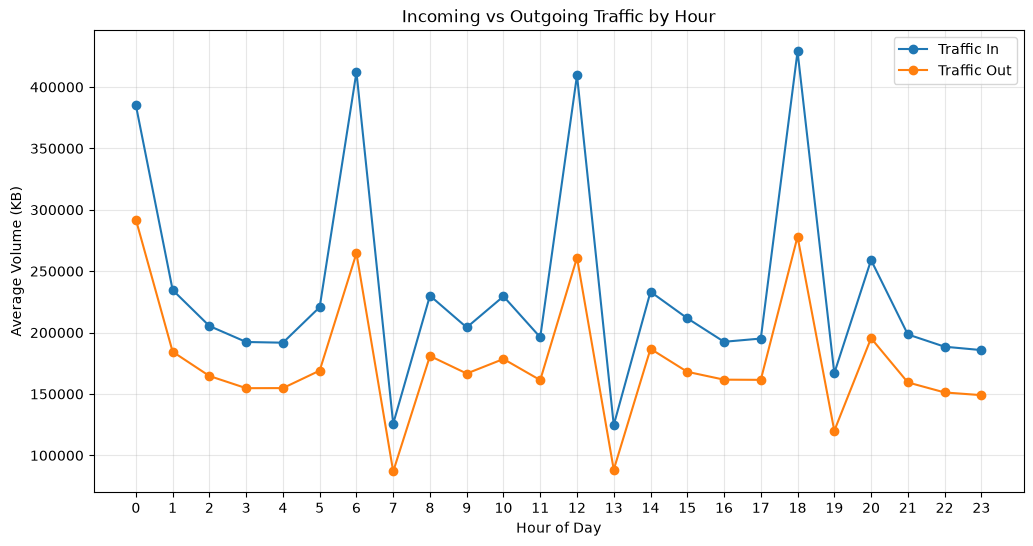

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(hourly_direction.index,hourly_direction["Traffic In (volume)"],marker="o",label="Traffic In")

plt.plot(hourly_direction.index,hourly_direction["Traffic Out (volume)"],marker="o",label="Traffic Out")

plt.xlabel("Hour of Day")
plt.ylabel("Average Volume (KB)")
plt.title("Incoming vs Outgoing Traffic by Hour")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [ ]:
hourly_speed = df.groupby("Hour")[["Traffic Total (speed)","Traffic In (speed)","Traffic Out (speed)"]].mean()


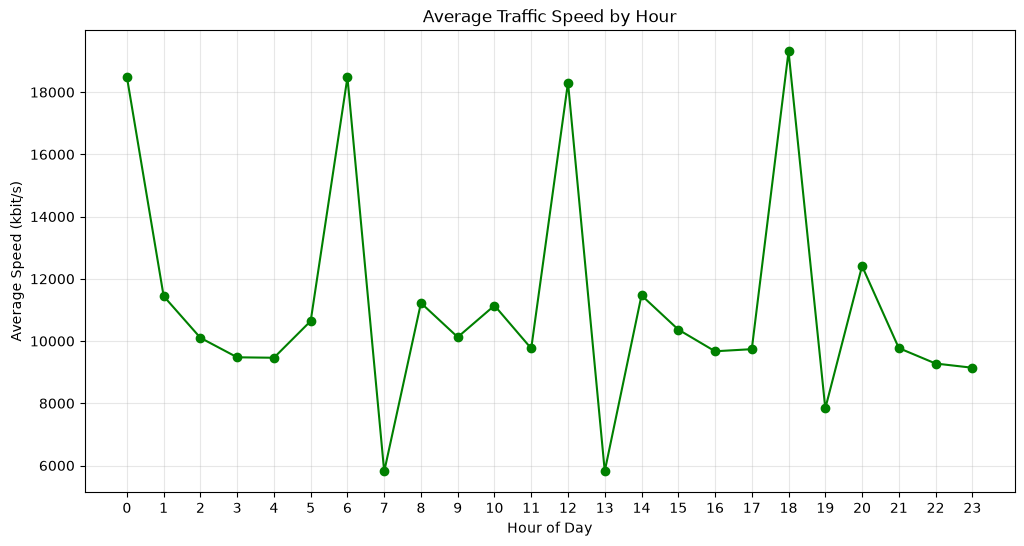

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(hourly_speed.index,hourly_speed["Traffic Total (speed)"],marker="o",color="green")

plt.xlabel("Hour of Day")
plt.ylabel("Average Speed (kbit/s)")
plt.title("Average Traffic Speed by Hour")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.show()


In [ ]:
peak_hour = hourly_volume.idxmax()
peak_volume = hourly_volume.max()

print("Peak hour:", peak_hour)
print("Average traffic volume:", peak_volume, "KB")


Peak hour: 18
Average traffic volume: 707019.7976190476 KB


In [ ]:
low_hour = hourly_volume.idxmin()
low_volume = hourly_volume.min()

print("Lowest traffic hour:", low_hour)
print("Average traffic volume:", low_volume, "KB")


Lowest traffic hour: 7
Average traffic volume: 212649.27083333334 KB


In [ ]:
hourly_summary = (df.groupby("Hour").agg({"Traffic Total (volume)": "mean","Traffic Total (speed)": "mean","Traffic In (volume)": "mean","Traffic Out (volume)": "mean"}).sort_values("Traffic Total (volume)", ascending=False))


In [ ]:
date_hour_volume = df.pivot_table(index=df["DateTime"].dt.date,columns="Hour",values="Traffic Total (volume)",aggfunc="mean")


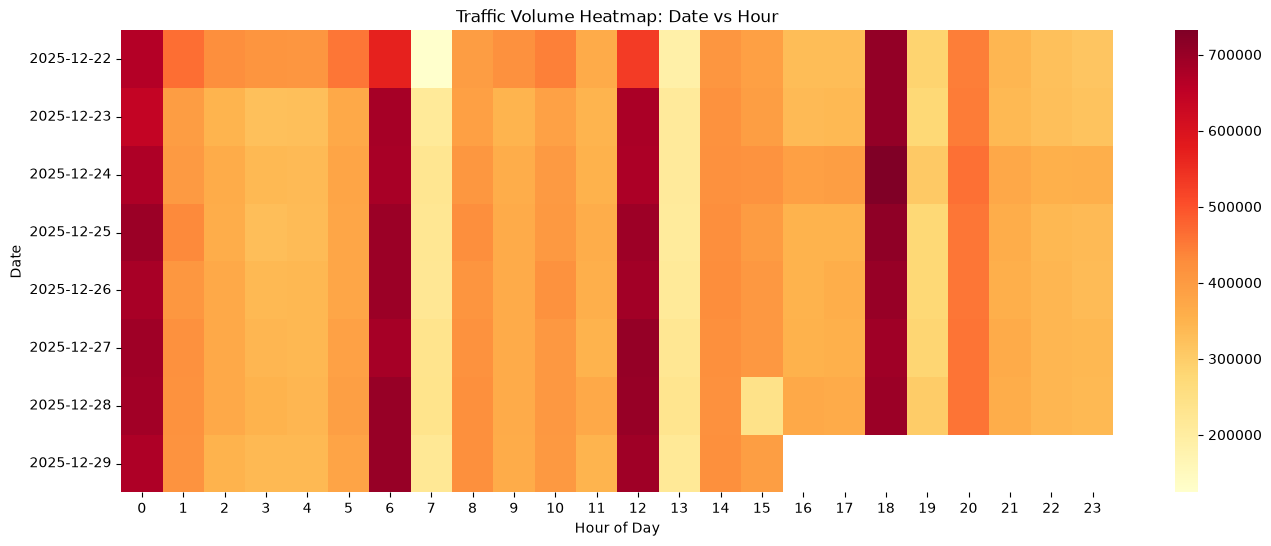

In [ ]:
plt.figure(figsize=(16, 6))

sns.heatmap(date_hour_volume,cmap="YlOrRd")

plt.xlabel("Hour of Day")
plt.ylabel("Date")
plt.title("Traffic Volume Heatmap: Date vs Hour")

plt.show()


Outlier Detection

In [ ]:
outlier_cols = ["Traffic Total (volume)","Traffic Total (speed)","Traffic In (volume)","Traffic In (speed)","Traffic Out (volume)","Traffic Out (speed)"]

In [ ]:
outlier_summary = []

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    outlier_summary.append({"Column": col,"Q1": Q1,"Q3": Q3,"IQR": IQR,"Lower Bound": lower_bound,"Upper Bound": upper_bound,"Outlier Count": len(outliers),"Outlier %": len(outliers) / len(df) * 100})

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary


,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,Traffic Total (volume),67152.00,403000.50,335848.50,-436620.750,906773.250,427,19.338768
1,Traffic Total (speed),1834.00,11005.50,9171.50,-11923.250,24762.750,427,19.338768
2,Traffic In (volume),37854.75,235685.00,197830.25,-258890.625,532430.375,418,18.931159
3,Traffic In (speed),1034.00,6436.25,5402.25,-7069.375,14539.625,418,18.931159
4,Traffic Out (volume),29464.75,169845.50,140380.75,-181106.375,380416.625,428,19.384058
5,Traffic Out (speed),804.75,4638.00,3833.25,-4945.125,10387.875,428,19.384058


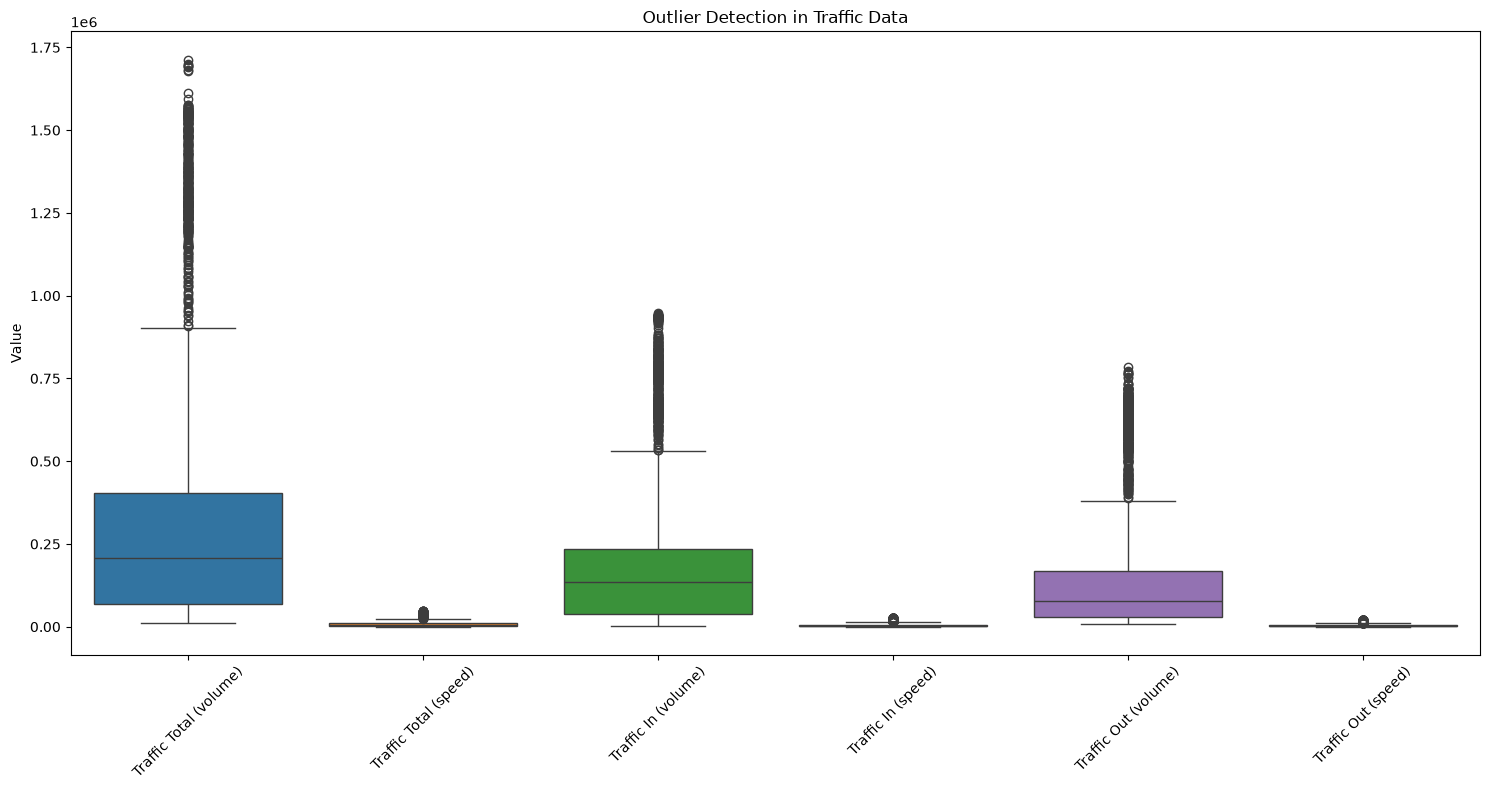

In [ ]:
plt.figure(figsize=(15, 8))

sns.boxplot(data=df[outlier_cols])

plt.title("Outlier Detection in Traffic Data")
plt.ylabel("Value")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [ ]:
Q1 = df["Traffic Total (volume)"].quantile(0.25)
Q3 = df["Traffic Total (volume)"].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print("Upper bound:", upper_bound)


Upper bound: 906773.25


In [ ]:
volume_outliers = df[
    df["Traffic Total (volume)"] > upper_bound].sort_values("Traffic Total (volume)",ascending=False)

volume_outliers[["DateTime","Traffic Total (volume)","Traffic In (volume)","Traffic Out (volume)"]].head(5)


,DateTime,Traffic Total (volume),Traffic In (volume),Traffic Out (volume)
2018,2025-12-29 00:10:00,1712855,927962,784893
1730,2025-12-28 00:10:00,1701269,928848,772421
1154,2025-12-26 00:10:00,1696131,927433,768698
1442,2025-12-27 00:10:00,1693490,926431,767059
866,2025-12-25 00:10:00,1693281,929722,763559


In [ ]:
peak_time = volume_outliers.iloc[0]["DateTime"]

df[(df["DateTime"] >= peak_time - pd.Timedelta(minutes=15)) & (df["DateTime"] <= peak_time + pd.Timedelta(minutes=15))][["DateTime","Traffic Total (volume)","Traffic Total (speed)","Traffic In (volume)","Traffic Out (volume)"]]


,DateTime,Traffic Total (volume),Traffic Total (speed),Traffic In (volume),Traffic Out (volume)
2015,2025-12-28 23:55:00,41717,1139,28401,13315
2016,2025-12-29 00:00:00,291250,7954,204550,86700
2017,2025-12-29 00:05:00,1548758,42294,872834,675924
2018,2025-12-29 00:10:00,1712855,46774,927962,784893
2019,2025-12-29 00:15:00,1029478,28115,607297,422181
2020,2025-12-29 00:20:00,36339,992,3769,32570
2021,2025-12-29 00:25:00,66563,1818,28059,38503


In [ ]:
Q1 = df["Traffic Total (volume)"].quantile(0.25)
Q3 = df["Traffic Total (volume)"].quantile(0.75)

IQR = Q3 - Q1

lower_volume = Q1 - 1.5 * IQR

low_volume_outliers = df[
    df["Traffic Total (volume)"] < lower_volume]

low_volume_outliers[["DateTime","Traffic Total (volume)","Traffic Total (speed)"]].head(5)


,DateTime,Traffic Total (volume),Traffic Total (speed)


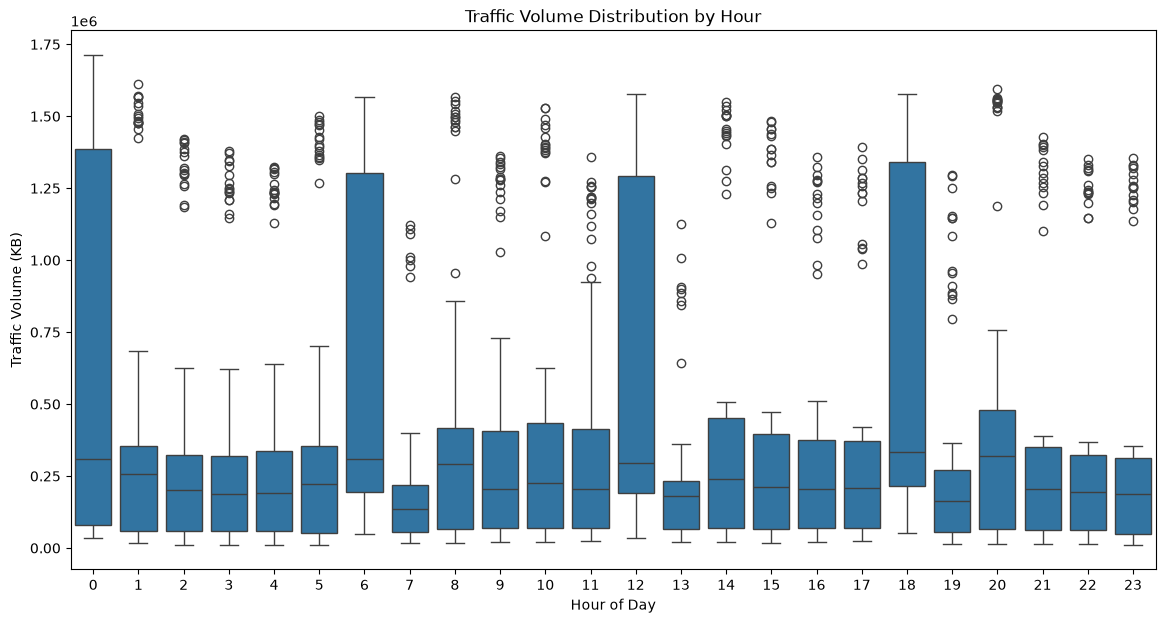

In [ ]:
plt.figure(figsize=(14, 7))

sns.boxplot(data=df,x="Hour",y="Traffic Total (volume)")

plt.xlabel("Hour of Day")
plt.ylabel("Traffic Volume (KB)")
plt.title("Traffic Volume Distribution by Hour")

plt.show()


Z - Score

In [ ]:
from scipy.stats import zscore


In [ ]:
df["Volume Z-Score"] = zscore(df["Traffic Total (volume)"])


In [ ]:
zscore_outliers = df[df["Volume Z-Score"].abs() > 3]

zscore_outliers[["DateTime","Traffic Total (volume)","Volume Z-Score"]].sort_values("Volume Z-Score",ascending=False)


,DateTime,Traffic Total (volume),Volume Z-Score


In [ ]:
print("IQR outliers:", len(volume_outliers))
print("Z-score outliers:", len(zscore_outliers))


IQR outliers: 427
Z-score outliers: 0


Correlation Analysis

In [ ]:
correlation_cols = ["Traffic Total (volume)","Traffic Total (speed)","Traffic In (volume)","Traffic In (speed)","Traffic Out (volume)","Traffic Out (speed)","Downtime","Coverage"]


In [ ]:
corr_matrix = df[correlation_cols].corr()


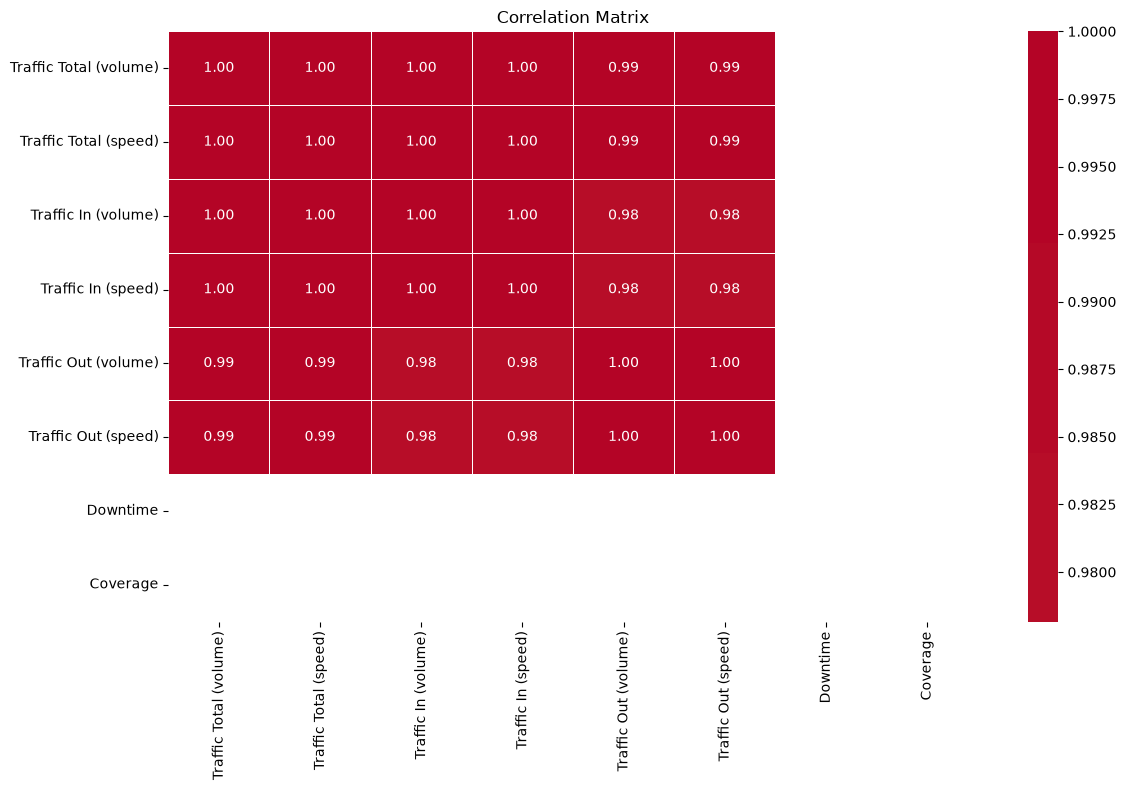

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(corr_matrix,annot=True,fmt=".2f",cmap="coolwarm",center=0,linewidths=0.5)

plt.title("Correlation Matrix")
plt.tight_layout()

plt.show()
